   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 225.7/225.7 kB 4.8 MB/s eta 0:00:00
=== VACCINE_VIRUS_LOG v2.0 | MODE = FAST | OWID Épidémiologie ===
  Source              : Our World in Data (OWID)
  Observations        : 2000 paires (pays, date)
  Période             : 2021-01-01 → 2023-12-31
  Estimations         : 1 | Fenêtre : 80 obs.
  Test statistique    : cohen_d
  Seuil (hypothèse)   : 65.0e percentile

Gradient de progression : 29 points

[1/6] Téléchargement données OWID (Our World in Data)...

[OWID] Téléchargement du dataset épidémiologique mondial...
  URL : https://raw.githubusercontent.com/owid/covid-19-data/master/public/data/owid-covid-data.csv
  Dataset brut : 429,435 lignes × 67 colonnes
  Après filtrage (données valides) : 55,821 observations
[OK] 2,000 observations | 184 pays/territoires
     Vaccination complète  : 46.8% (moyenne)
     Nouveaux cas/million  : 326.3 (moyenne, lissés)
     Population ≥65 ans    : 12.0% (moyenne)

[2/6] Extraction des 5 flux vaccin+viru

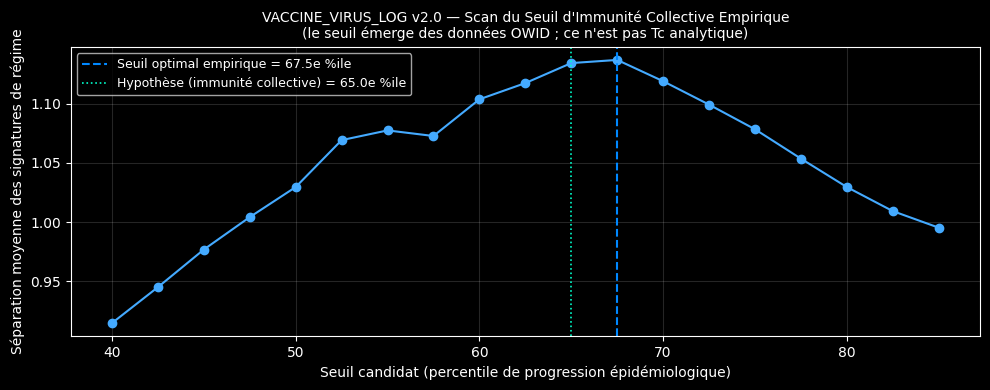


[Scan du seuil critique]
  Hypothèse initiale (immunité collective) : 65.0e percentile
  Seuil optimal OWID                       : 67.5e percentile (séparation = 1.137)

[4/6] Vue d'ensemble épidémiologique OWID + profils des 5 flux...


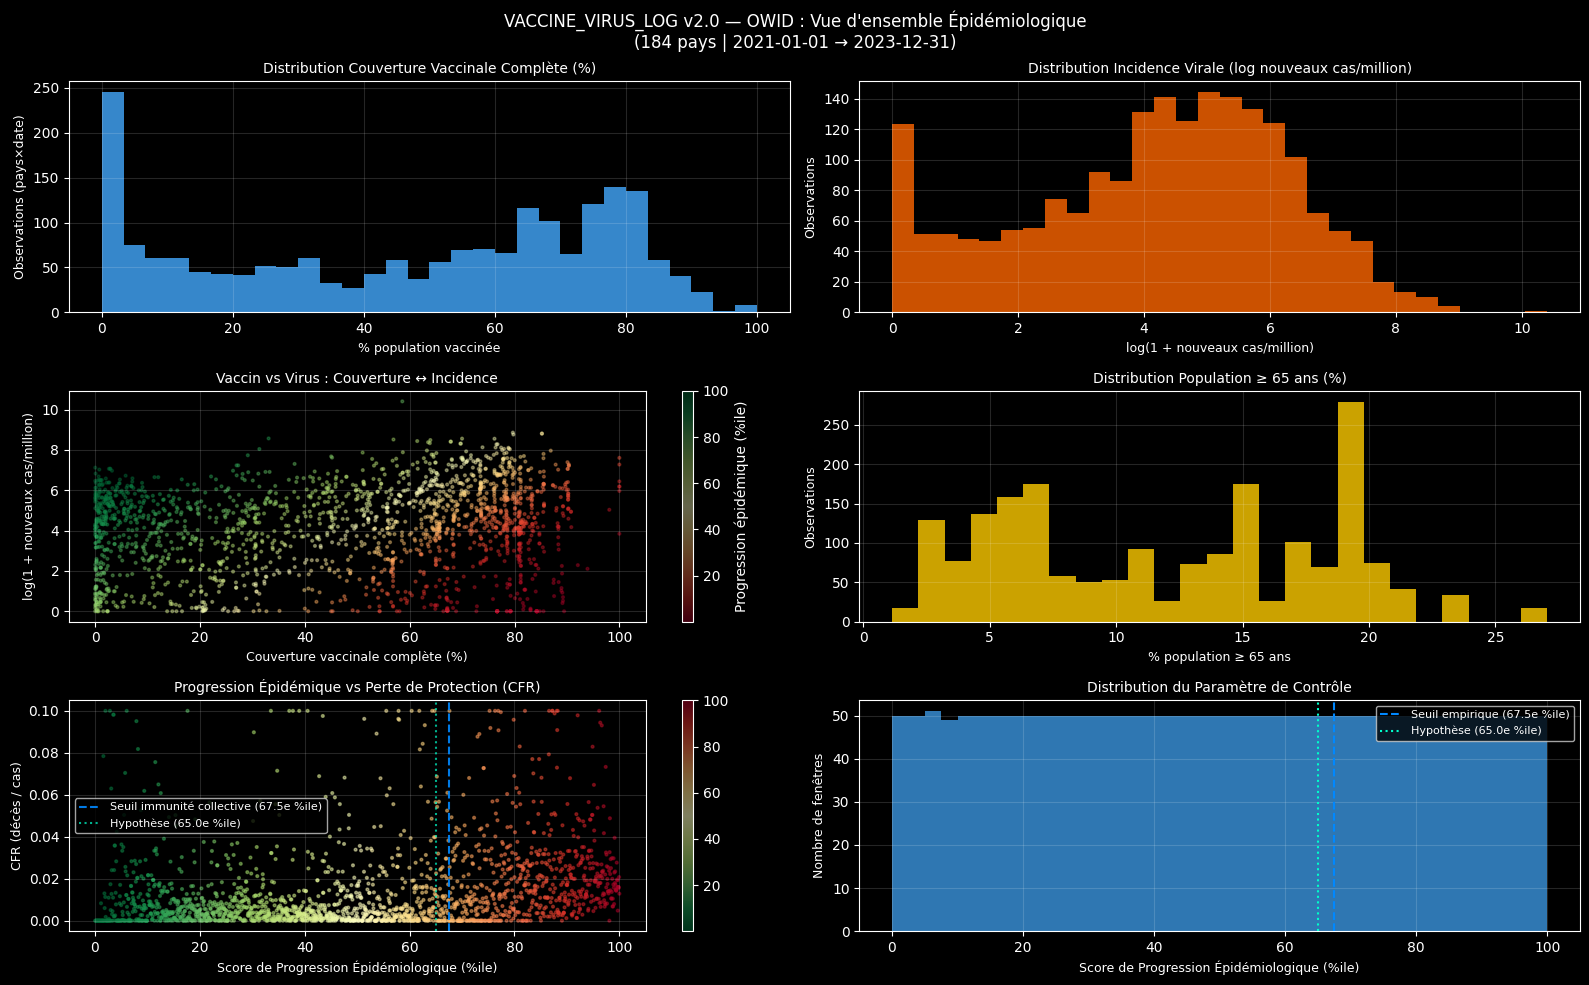

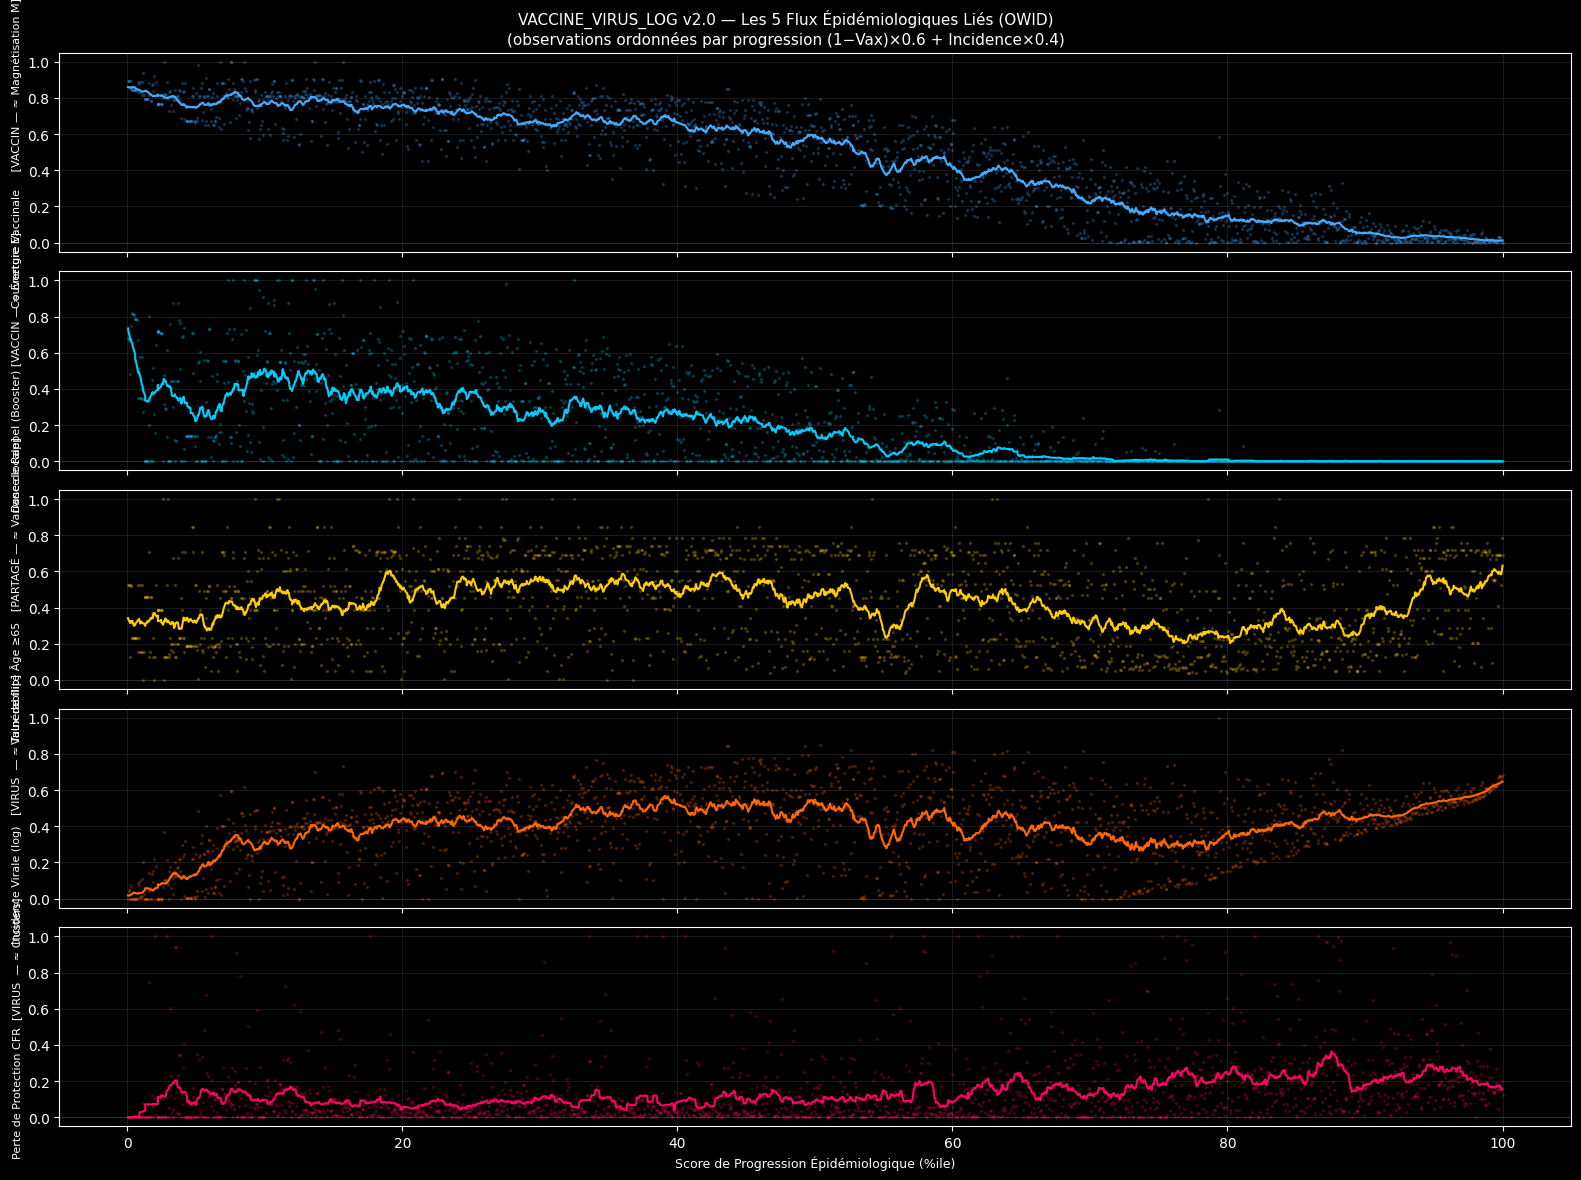


[5/6] Extraction des signatures de régime épidémiologique...

[Extraction des signatures de régime] 1 cohorte unique | Fenêtre=80 obs.


Scan de progression épidémiologique: 100%|██████████| 29/29 [04:29<00:00,  9.29s/it]


  Signatures extraites : 25
   Progress  N_cohorts  Vaccination_Signal_Higuchi_mean  Vaccination_Signal_DFA_mean  Vaccination_Signal_Katz_mean  Vaccination_Signal_Hurst_mean
0       5.0        120                         2.032834                     1.977925                     10.040916                       0.079274
1      10.0        120                         2.045725                     1.988541                     10.680138                       0.054829
2      15.0        120                         2.054210                     1.993081                      8.958913                       0.062703


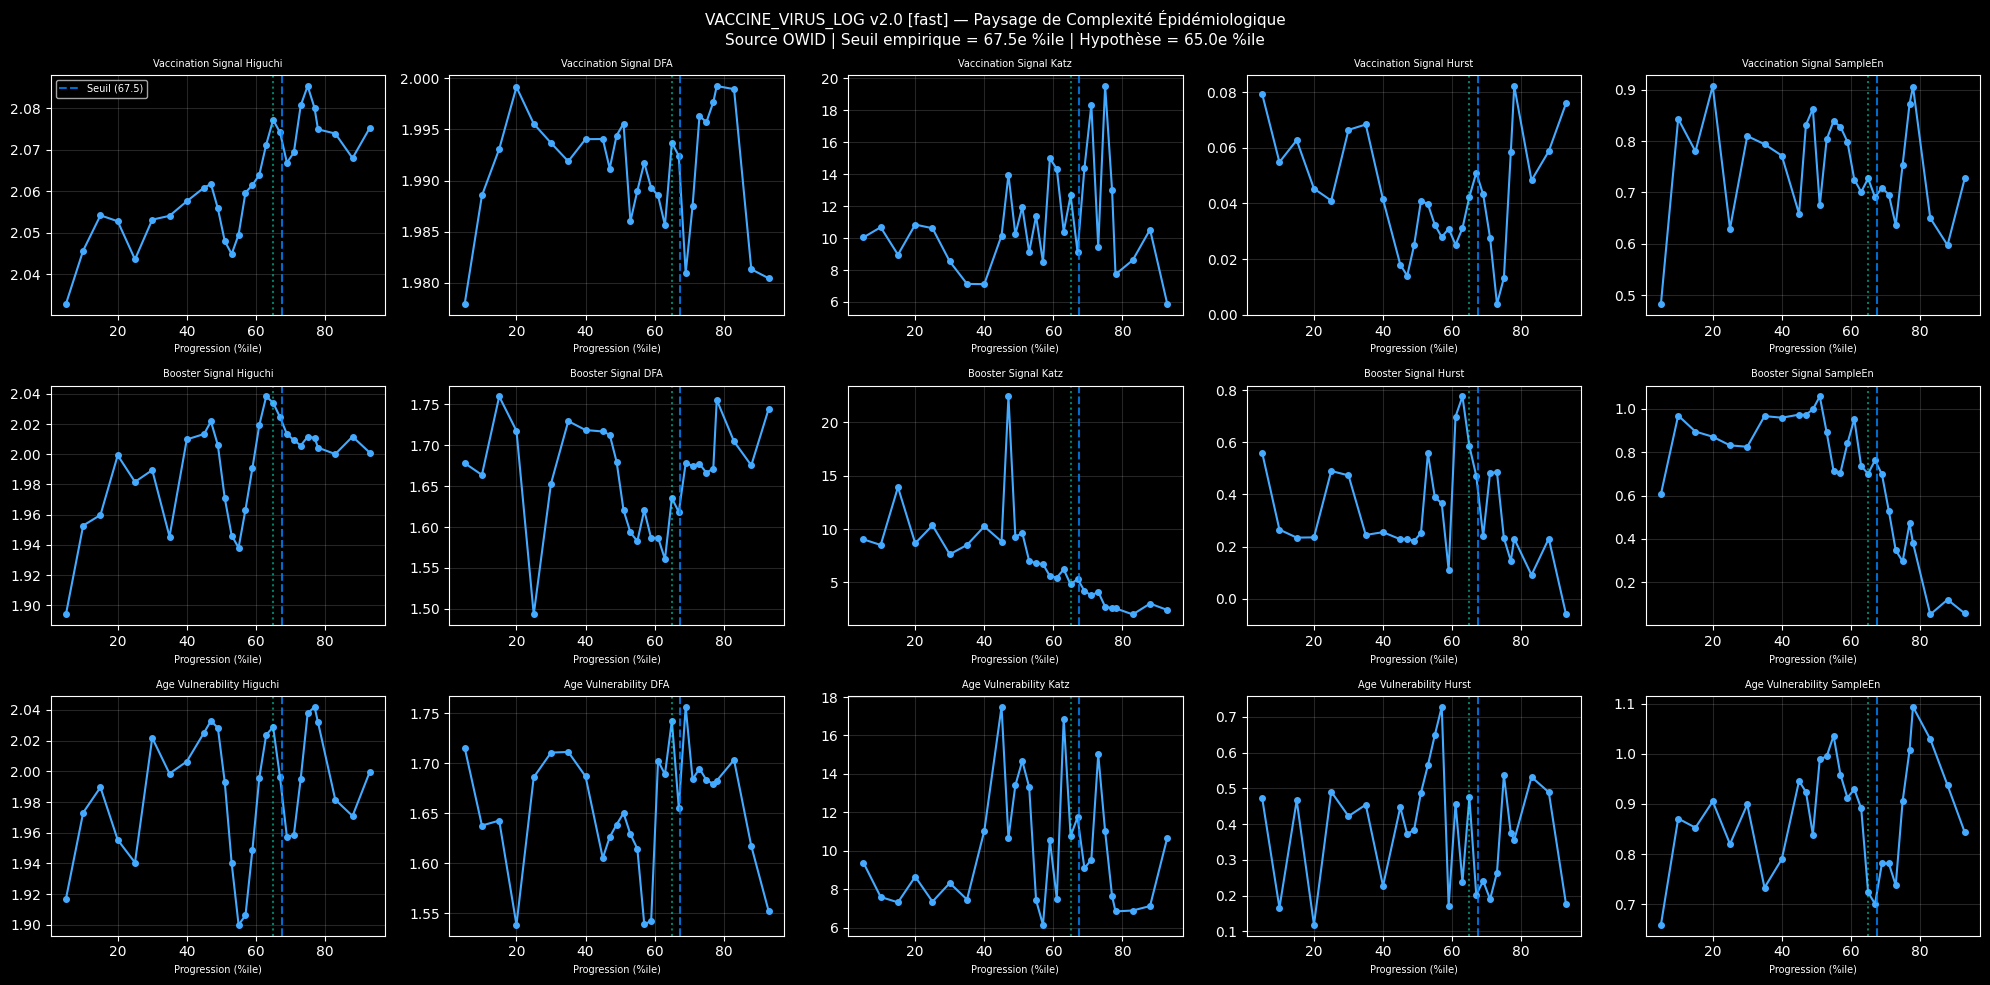


[6/6] 4 Questions Épidémiologiques...

=== 4 Questions Épidémiologiques (seuil empirique = 67.5e %ile) ===
Q1 : Population Protégée vs Vulnérable (0–40e %ile vs 70–100e %ile)...
Q2 : Tension au Seuil d'Immunité Collective (zone de basculement)...
Q3 : Vulnérabilité Âge × Virus (flux démographiques + viraux)...
Q4 : Persistance du Régime Épidémique (hystérésis intra-cohorte)...

>>> RÉSULTATS — Scores de séparation des signatures de régime :
                                  Q1_Protegee_vs_Vulnerable  Q2_Tension_Immunite_Collective  Q3_Vulnerabilite_Age_Virus  Q4_Persistance_Regime_Epidemique
Age_Vulnerability_DFA_mean                            0.072                           0.907                       0.118                             0.213
Age_Vulnerability_Higuchi_mean                        0.797                           0.992                       1.041                             0.213
Age_Vulnerability_Hurst_mean                          0.084                           0.532 

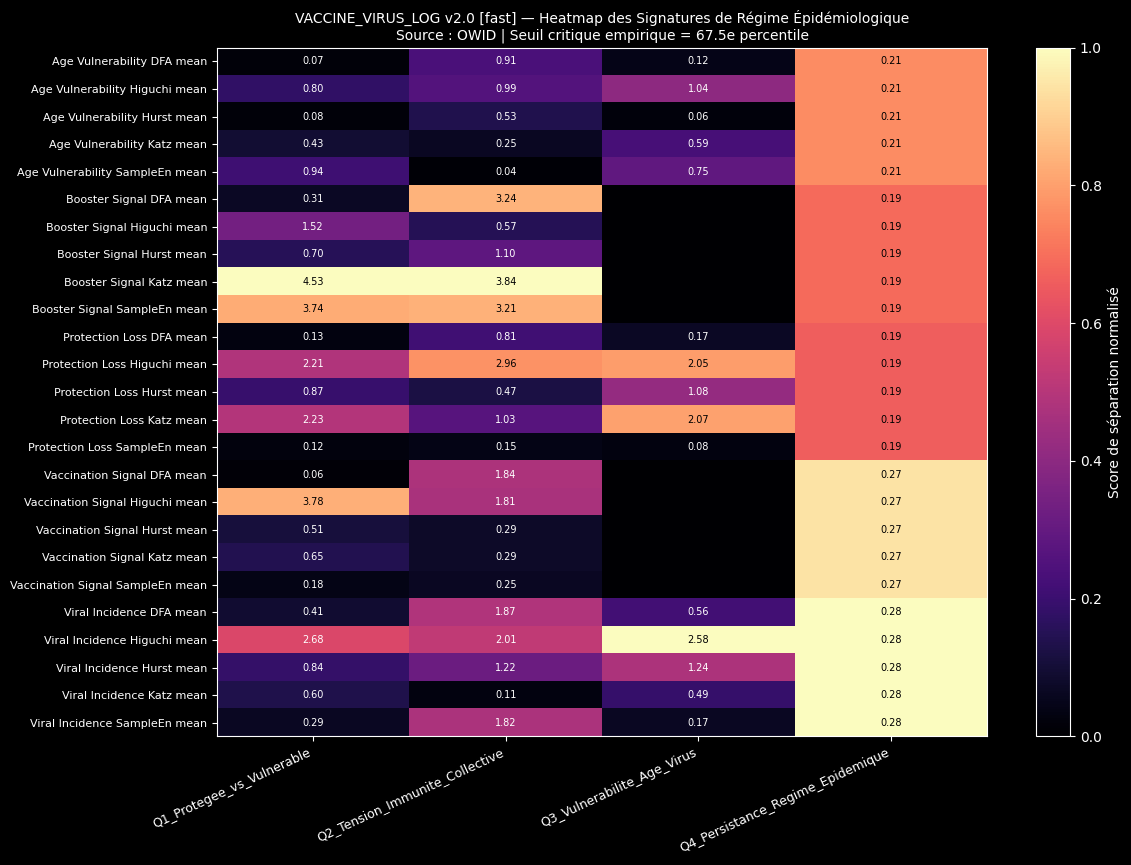


[OK] VACCINE_VIRUS_LOG v2.0 terminé.
     2,000 observations OWID | 184 pays
     Période : 2021-01-01 → 2023-12-31
     Seuil d'immunité collective empirique : 67.5e percentile
     Hypothèse initiale                    : 65.0e percentile
     Mode : FAST | Estimateurs : Higuchi, DFA, Katz, Hurst, SampleEn


In [1]:
# ============================================================================
# VACCINE_VIRUS_LOG v2.0
# Analyse épidémiologique Vaccin ↔ Virus — Données réelles OWID + WHO FluNet
# Architecture identique à BIO_CANCER_LOG (Fast/Robust, estimateurs, graphiques)
#
# SOURCE : Our World in Data (OWID) COVID-19 dataset
#   → Résout le problème du dénominateur (cohortes entières, vaccinés + non vaccinés)
#   → Données de niveau population (≈ 220 pays × ~1000 jours = ~200 000 observations)
#   → Chaque ligne = une observation (pays, date) = analogue d'un patient
#
# 5 FLUX LIÉS (vaccin ↔ virus) :
#   [VACCIN 1] Vaccination_Signal    — couverture vaccinale complète (0–1)
#   [VACCIN 2] Booster_Signal        — dose de rappel / renforcement immun (0–1)
#   [PARTAGÉ]  Age_Vulnerability     — % population ≥65 ans (vulnérabilité structurelle)
#   [VIRUS  1] Viral_Incidence       — nouveaux cas lissés par million (log-normalisé)
#   [VIRUS  2] Protection_Loss       — ratio décès/cas = échec de protection (CFR normalisé)
#
# PARAMÈTRE DE CONTRÔLE (analogue Stage×Grade) :
#   Progress = (1 − vaccination) × 0.6 + incidence_virale × 0.4
#   Bas %ile  = forte couverture + faible incidence → population protégée
#   Haut %ile = faible couverture + forte incidence → percée virale / rupture immunitaire
#
# SEUIL CRITIQUE (analogue EMT) :
#   Point de bascule épidémiologique : seuil d'immunité collective empirique
# ============================================================================

!pip install -q nolds antropy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy import stats
import requests, json, io
import warnings
warnings.filterwarnings('ignore')
import antropy, nolds

plt.style.use('dark_background')

# -----------------------------------------------------------
# MODE : 'fast' ou 'robust'
# -----------------------------------------------------------
MODE = 'fast'

# Hypothèse : le seuil critique (transition protection → percée virale)
# correspond à ~65e percentile de la progression épidémiologique composite.
PROGRESS_CRITIQUE_HYPOTHESE = 65.0

# Nombre d'observations (paires pays×date) à utiliser
N_OBSERVATIONS = 2000

# Filtres temporels — phase vaccinale principale (données les plus riches)
DATE_MIN = '2021-01-01'
DATE_MAX = '2023-12-31'

# URL OWID — dataset épidémiologique mondial, mis à jour quotidiennement
OWID_URL = (
    "https://raw.githubusercontent.com/owid/covid-19-data/master/"
    "public/data/owid-covid-data.csv"
)

CONFIG = {
    'fast': {
        'n_estimations':     1,
        'window_size':       80,
        'stat_test':         'cohen_d',
        'min_per_group':     2,
        'estimator_min_len': 50,
        'mann_whitney':      False,
        'bootstrap':         False,
    },
    'robust': {
        'n_estimations':     5,
        'window_size':       150,
        'stat_test':         'cliff_delta',
        'min_per_group':     3,
        'estimator_min_len': 80,
        'mann_whitney':      True,
        'bootstrap':         True,
    }
}
C = CONFIG[MODE]
print(f"=== VACCINE_VIRUS_LOG v2.0 | MODE = {MODE.upper()} | OWID Épidémiologie ===")
print(f"  Source              : Our World in Data (OWID)")
print(f"  Observations        : {N_OBSERVATIONS} paires (pays, date)")
print(f"  Période             : {DATE_MIN} → {DATE_MAX}")
print(f"  Estimations         : {C['n_estimations']} | Fenêtre : {C['window_size']} obs.")
print(f"  Test statistique    : {C['stat_test']}")
print(f"  Seuil (hypothèse)   : {PROGRESS_CRITIQUE_HYPOTHESE}e percentile")

# =============================================================================
# 0. STATISTIQUES  ← identique BIO_CANCER_LOG, aucun changement
# =============================================================================

def cohen_d(g1, g2):
    g1, g2 = np.asarray(g1), np.asarray(g2)
    if len(g1) < 2 or len(g2) < 2: return np.nan
    pooled_std = np.sqrt((np.var(g1, ddof=1) + np.var(g2, ddof=1)) / 2.0)
    return 0.0 if pooled_std < 1e-12 else (np.mean(g1) - np.mean(g2)) / pooled_std

def cliff_delta(g1, g2):
    g1, g2 = np.asarray(g1), np.asarray(g2)
    n1, n2 = len(g1), len(g2)
    if n1 < C['min_per_group'] or n2 < C['min_per_group']: return np.nan, np.nan
    try:
        U, _ = stats.mannwhitneyu(g1, g2, alternative='two-sided')
        return np.clip((2 * U - n1 * n2) / (n1 * n2), -1, 1), np.nan
    except: return np.nan, np.nan

def separation_score(g1, g2):
    if C['stat_test'] == 'cohen_d':
        d = cohen_d(g1, g2)
        return abs(d) if not np.isnan(d) else np.nan
    else:
        d, _ = cliff_delta(g1, g2)
        return abs(d) if not np.isnan(d) else np.nan

def mw_score(g1, g2):
    if not C['mann_whitney']: return np.nan
    try:
        _, p = stats.mannwhitneyu(g1, g2, alternative='two-sided')
        return -np.log10(max(p, 1e-300))
    except: return np.nan

# =============================================================================
# 1. ACQUISITION — Our World in Data (OWID)
#
#  Résout le problème du dénominateur de VAERS :
#  → On suit des COHORTES ENTIÈRES (pays entiers), pas seulement les cas déclarés.
#  → Chaque ligne = (pays, date) = une unité d'observation épidémiologique.
#
#  FLUX VACCIN :
#    Vaccination_Signal  — % population entièrement vaccinée   [0, 1]
#    Booster_Signal      — % population avec dose de rappel    [0, 1]
#
#  FLUX PARTAGÉ :
#    Age_Vulnerability   — % population ≥ 65 ans (normalisé)   [0, 1]
#
#  FLUX VIRUS :
#    Viral_Incidence     — nouveaux cas lissés / million (log-normalisé) [0, 1]
#    Protection_Loss     — CFR normalisé = décès / (cas + ε)             [0, 1]
# =============================================================================

def fetch_owid_data(n_obs=N_OBSERVATIONS,
                    date_min=DATE_MIN,
                    date_max=DATE_MAX):
    """
    Télécharge le dataset OWID (Our World in Data) depuis GitHub.
    Filtre les lignes exploitables (pays avec données vaccinales + virologiques).
    Retourne un DataFrame de n_obs observations (pays × date).

    Champs utilisés :
      people_fully_vaccinated_per_hundred → couverture vaccinale complète
      total_boosters_per_hundred          → couverture rappels
      aged_65_older                       → vulnérabilité démographique
      new_cases_smoothed_per_million      → incidence virale lissée
      new_deaths_smoothed_per_million     → mortalité virale lissée
    """
    print(f"\n[OWID] Téléchargement du dataset épidémiologique mondial...")
    print(f"  URL : {OWID_URL}")

    try:
        resp = requests.get(OWID_URL, timeout=120)
        resp.raise_for_status()
    except Exception as e:
        raise ConnectionError(
            f"Impossible de télécharger OWID : {e}\n"
            "Vérifiez la connexion internet."
        )

    raw = pd.read_csv(io.StringIO(resp.text), low_memory=False)
    print(f"  Dataset brut : {len(raw):,} lignes × {len(raw.columns)} colonnes")

    # --- Filtrage ---------------------------------------------------------

    # Exclure les agrégats continentaux / mondiaux (iso_code commence par OWID_)
    raw = raw[~raw['iso_code'].astype(str).str.startswith('OWID_')]

    # Fenêtre temporelle
    raw['date'] = pd.to_datetime(raw['date'], errors='coerce')
    raw = raw[(raw['date'] >= date_min) & (raw['date'] <= date_max)]

    # Colonnes nécessaires
    needed = [
        'iso_code', 'location', 'date', 'continent',
        'people_fully_vaccinated_per_hundred',
        'total_boosters_per_hundred',
        'aged_65_older',
        'new_cases_smoothed_per_million',
        'new_deaths_smoothed_per_million',
        'population',
    ]
    # Garder seulement les colonnes disponibles
    available = [c for c in needed if c in raw.columns]
    df = raw[available].copy()

    # Convertir en numérique
    num_cols = [c for c in available if c not in ('iso_code','location','date','continent')]
    for col in num_cols:
        df[col] = pd.to_numeric(df[col], errors='coerce')

    # Clip valeurs aberrantes
    df['people_fully_vaccinated_per_hundred'] = \
        df['people_fully_vaccinated_per_hundred'].clip(0, 100)
    df['total_boosters_per_hundred'] = \
        df['total_boosters_per_hundred'].clip(0, 200)
    df['new_cases_smoothed_per_million'] = \
        df['new_cases_smoothed_per_million'].clip(lower=0)
    df['new_deaths_smoothed_per_million'] = \
        df['new_deaths_smoothed_per_million'].clip(lower=0)

    # Garder uniquement les lignes avec au moins les données vaccinales + cas
    df = df.dropna(subset=[
        'people_fully_vaccinated_per_hundred',
        'new_cases_smoothed_per_million'
    ]).reset_index(drop=True)

    print(f"  Après filtrage (données valides) : {len(df):,} observations")

    if len(df) == 0:
        raise ValueError(
            "Aucune observation valide après filtrage. "
            "Vérifiez DATE_MIN/DATE_MAX et la connexion."
        )

    # Échantillonnage stratifié si trop d'observations
    if len(df) > n_obs:
        # Stratifier par continent pour garder la diversité mondiale
        if 'continent' in df.columns:
            df = (df.groupby('continent', group_keys=False)
                    .apply(lambda g: g.sample(
                        min(len(g), max(1, int(n_obs * len(g) / len(df)))),
                        random_state=42))
                    .reset_index(drop=True))
            # Compléter si nécessaire
            if len(df) < n_obs:
                extra = df.sample(min(n_obs - len(df), len(df)), random_state=1)
                df = pd.concat([df, extra]).reset_index(drop=True)
        else:
            df = df.sample(n_obs, random_state=42).reset_index(drop=True)
        df = df.head(n_obs)

    # Statistiques descriptives
    n_countries = df['iso_code'].nunique() if 'iso_code' in df.columns else '?'
    vax_mean = df['people_fully_vaccinated_per_hundred'].mean()
    cases_mean = df['new_cases_smoothed_per_million'].mean()
    print(f"[OK] {len(df):,} observations | {n_countries} pays/territoires")
    print(f"     Vaccination complète  : {vax_mean:.1f}% (moyenne)")
    print(f"     Nouveaux cas/million  : {cases_mean:.1f} (moyenne, lissés)")
    if 'aged_65_older' in df.columns:
        age_mean = df['aged_65_older'].dropna().mean()
        print(f"     Population ≥65 ans    : {age_mean:.1f}% (moyenne)")
    return df


# ---- Encodeurs ---------------------------------------------------------------

def log_normalize(series, eps=1e-3):
    """Normalisation log-min-max robuste pour les distributions à longue queue."""
    s = np.log1p(series.clip(lower=0).fillna(0))
    s_min, s_max = s.min(), s.max()
    if s_max - s_min < 1e-10: return pd.Series(np.zeros(len(series)))
    return (s - s_min) / (s_max - s_min)

def minmax_normalize(series):
    """Normalisation min-max simple."""
    s = series.fillna(series.median())
    s_min, s_max = s.min(), s.max()
    if s_max - s_min < 1e-10: return pd.Series(np.full(len(series), 0.5))
    return (s - s_min) / (s_max - s_min)

# ---- Extraction des 5 flux --------------------------------------------------

def extract_epi_fluxes(df):
    """
    Extrait 5 flux épidémiologiques à partir des données OWID.

    VACCIN (côté immunisation) :
      Vaccination_Signal  — couverture vaccinale complète [0, 1]
                            Haut = forte protection de masse
      Booster_Signal      — dose de rappel [0, 1]
                            Haut = renforcement immunitaire de la population

    PARTAGÉ :
      Age_Vulnerability   — % population ≥ 65 ans (normalisé) [0, 1]
                            Haut = population structurellement vulnérable

    VIRUS (côté infection) :
      Viral_Incidence     — incidence virale log-normalisée [0, 1]
                            Haut = forte pression du virus
      Protection_Loss     — CFR normalisé (décès/cas) [0, 1]
                            Haut = la protection vaccinale échoue à prévenir les décès

    Analogie BIO_CANCER_LOG :
      Stage_Signal        ↔ Vaccination_Signal   (paramètre de progression principal)
      Grade_Signal        ↔ Booster_Signal        (renforcement / agressivité)
      Age_Signal          ↔ Age_Vulnerability     (modulateur partagé)
      Lethality_Signal    ↔ Viral_Incidence        (intensité du pathogène)
      Survival_Loss       ↔ Protection_Loss        (échec de survie / protection)
    """
    out = {}

    # --- FLUX VACCIN 1 : Couverture vaccinale complète
    vax = df['people_fully_vaccinated_per_hundred'].fillna(0) / 100.0
    out['Vaccination_Signal'] = vax.clip(0, 1).values

    # --- FLUX VACCIN 2 : Dose de rappel (booster)
    if 'total_boosters_per_hundred' in df.columns:
        boost_raw = df['total_boosters_per_hundred'].fillna(0)
        # Normaliser sur 100 (certains pays dépassent 100% = doses multiples)
        boost_norm = boost_raw / boost_raw.clip(lower=1e-3).quantile(0.99)
        out['Booster_Signal'] = boost_norm.clip(0, 1).values
    else:
        # Proxy : dérivée de la couverture vaccinale si booster absent
        out['Booster_Signal'] = np.gradient(
            df['people_fully_vaccinated_per_hundred'].fillna(0).values
        ).clip(0, None)
        out['Booster_Signal'] = (out['Booster_Signal'] /
                                  (out['Booster_Signal'].max() + 1e-10))

    # --- FLUX PARTAGÉ : Vulnérabilité démographique (âge ≥ 65 ans)
    if 'aged_65_older' in df.columns:
        age_vuln = minmax_normalize(df['aged_65_older'])
    else:
        age_vuln = pd.Series(np.full(len(df), 0.5))
    out['Age_Vulnerability'] = age_vuln.values

    # --- FLUX VIRUS 1 : Incidence virale log-normalisée
    out['Viral_Incidence'] = log_normalize(
        df['new_cases_smoothed_per_million']
    ).values

    # --- FLUX VIRUS 2 : Perte de protection (CFR normalisé)
    #   CFR brut = décès / cas  (sans log pour rester proportionnel)
    #   Clampé à [0, 0.20] pour exclure les outliers de début de pandémie
    cases  = df['new_cases_smoothed_per_million'].clip(lower=1e-3).fillna(1e-3)
    if 'new_deaths_smoothed_per_million' in df.columns:
        deaths = df['new_deaths_smoothed_per_million'].clip(lower=0).fillna(0)
    else:
        deaths = pd.Series(np.zeros(len(df)))
    cfr_raw  = (deaths / cases).clip(0, 0.20)
    cfr_norm = cfr_raw / (cfr_raw.quantile(0.99) + 1e-10)
    out['Protection_Loss'] = cfr_norm.clip(0, 1).values

    return out


# ---- Paramètre de contrôle (progression épidémiologique) --------------------

def compute_epi_progression(df):
    """
    Paramètre de contrôle épidémiologique composite :

      Progress = (1 − Vaccination_norm) × 0.6 + Viral_Incidence_norm × 0.4

    Analogie exacte avec BIO_CANCER_LOG :
      Stage×0.6 + Grade×0.4  →  (1−Vax)×0.6 + IncidenceVirale×0.4

    Interprétation :
      Bas percentile  = forte vaccination + faible incidence → population protégée
      Haut percentile = faible vaccination + forte incidence → percée virale / rupture

    Le seuil critique = point de bascule épidémiologique empirique
    (analogue du seuil EMT en cancérologie).
    """
    vax_norm  = df['people_fully_vaccinated_per_hundred'].fillna(0) / 100.0
    vax_norm  = vax_norm.clip(0, 1)
    viral_raw = df['new_cases_smoothed_per_million'].clip(lower=0).fillna(0)
    viral_norm = log_normalize(viral_raw)

    composite = (1.0 - vax_norm) * 0.6 + viral_norm * 0.4
    return np.array([stats.percentileofscore(composite, v) for v in composite])


# =============================================================================
# 2. SCAN DU SEUIL CRITIQUE  ← architecture identique BIO_CANCER_LOG
#    "Seuil EMT tumoral"  →  "Seuil d'immunité collective empirique"
# =============================================================================

def scan_seuil_critique(df, fluxes, progress_series, candidats=None):
    if candidats is None:
        candidats = np.arange(40, 86, 2.5)

    W         = C['window_size']
    flux_keys = list(fluxes.keys())
    n_obs     = len(df)
    sort_idx  = np.argsort(progress_series)
    prog_s    = progress_series[sort_idx]
    flux_s    = {k: v[sort_idx] for k, v in fluxes.items()}

    windows = []
    for i in range(n_obs - W + 1):
        windows.append({
            'progress': float(np.mean(prog_s[i:i+W])),
            'data':     {k: flux_s[k][i:i+W] for k in flux_keys}
        })

    if not windows:
        raise ValueError(
            f"Pas assez d'observations ({n_obs}) pour la fenêtre de {W}. "
            "Augmentez N_OBSERVATIONS ou réduisez window_size."
        )

    scores_par_seuil = []
    for seuil in candidats:
        grp_bas  = [w for w in windows if w['progress'] <  seuil]
        grp_haut = [w for w in windows if w['progress'] >= seuil]
        if (len(grp_bas)  < C['min_per_group'] or
                len(grp_haut) < C['min_per_group']):
            scores_par_seuil.append(np.nan)
            continue
        sep = []
        for k in flux_keys:
            d = separation_score(
                np.concatenate([w['data'][k] for w in grp_bas]),
                np.concatenate([w['data'][k] for w in grp_haut])
            )
            if not np.isnan(d): sep.append(d)
        scores_par_seuil.append(np.mean(sep) if sep else np.nan)

    scores_arr = np.array(scores_par_seuil, dtype=float)
    idx_max    = np.nanargmax(scores_arr)
    seuil_opt  = candidats[idx_max]

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(candidats, scores_arr, 'o-', color='#44aaff', markersize=6)
    ax.axvline(seuil_opt, color='#0088ff', linestyle='--', linewidth=1.5,
               label=f'Seuil optimal empirique = {seuil_opt:.1f}e %ile')
    ax.axvline(PROGRESS_CRITIQUE_HYPOTHESE, color='#00ffcc', linestyle=':', linewidth=1.2,
               label=f'Hypothèse (immunité collective) = {PROGRESS_CRITIQUE_HYPOTHESE}e %ile')
    ax.set_xlabel('Seuil candidat (percentile de progression épidémiologique)', fontsize=10)
    ax.set_ylabel('Séparation moyenne des signatures de régime', fontsize=10)
    ax.set_title(
        'VACCINE_VIRUS_LOG v2.0 — Scan du Seuil d\'Immunité Collective Empirique\n'
        '(le seuil émerge des données OWID ; ce n\'est pas Tc analytique)',
        fontsize=10)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.15)
    plt.tight_layout()
    plt.show()

    print(f"\n[Scan du seuil critique]")
    print(f"  Hypothèse initiale (immunité collective) : {PROGRESS_CRITIQUE_HYPOTHESE}e percentile")
    print(f"  Seuil optimal OWID                       : {seuil_opt:.1f}e percentile "
          f"(séparation = {scores_arr[idx_max]:.3f})")
    return seuil_opt, candidats, scores_arr, windows


# =============================================================================
# 3. ESTIMATEURS DE COMPLEXITÉ  ← identique BIO_CANCER_LOG, aucun changement
#    Higuchi FD | DFA | Katz FD | Hurst RS | Sample Entropy
# =============================================================================

def apply_estimators(series, flux_name=''):
    s = np.asarray(series).flatten()
    min_len = C['estimator_min_len']
    if len(s) < min_len:
        return {k: np.nan for k in ['Higuchi','DFA','Katz','Hurst','SampleEn']}
    # Flux à variance binaire ou très faible → différencier avant analyse
    if flux_name in ('Vaccination_Signal', 'Protection_Loss') and np.std(s) > 1e-10:
        s = np.diff(s)
    if np.std(s) > 1e-10:
        s = (s - np.mean(s)) / np.std(s)
    if len(s) < min_len:
        return {k: np.nan for k in ['Higuchi','DFA','Katz','Hurst','SampleEn']}
    est = {}
    try:   est['Higuchi']  = antropy.higuchi_fd(s)
    except: est['Higuchi']  = np.nan
    try:   est['DFA']      = 2.0 - nolds.dfa(s)
    except: est['DFA']      = np.nan
    try:   est['Katz']     = antropy.katz_fd(s)
    except: est['Katz']     = np.nan
    try:   est['Hurst']    = nolds.hurst_rs(s)
    except: est['Hurst']    = np.nan
    try:   est['SampleEn'] = antropy.sample_entropy(s[:min(500, len(s))], order=2)
    except: est['SampleEn'] = np.nan
    return est

    # =============================================================================
# 4. PIPELINE  ← architecture identique BIO_CANCER_LOG
#    build_cancer_features → build_epi_features
# =============================================================================

def build_epi_features(df, fluxes, progress_series, progress_values):
    W   = C['window_size']
    n   = C['n_estimations']
    tol = max(3.0, (progress_values[1]-progress_values[0])/2.0) \
          if len(progress_values) > 1 else 3.0

    mode_label = (
        "bootstrap sur sous-cohortes (stabilité statistique)"
        if C['bootstrap'] else "cohorte unique"
    )
    print(f"\n[Extraction des signatures de régime] {n} {mode_label} | Fenêtre={W} obs.")

    sort_idx    = np.argsort(progress_series)
    prog_sorted = progress_series[sort_idx]
    flux_sorted = {k: v[sort_idx] for k, v in fluxes.items()}
    flux_keys   = list(fluxes.keys())
    n_obs       = len(df)

    window_data = []
    for i in range(n_obs - W + 1):
        window_data.append({
            'progress': float(np.mean(prog_sorted[i:i+W])),
            'fluxes':   {k: flux_sorted[k][i:i+W] for k in flux_keys}
        })

    rows = []
    for P in tqdm(progress_values, desc="Scan de progression épidémiologique"):
        matching = [w for w in window_data if abs(w['progress'] - P) <= tol]
        if not matching:
            matching = [min(window_data, key=lambda w: abs(w['progress'] - P))]
        row = {'Progress': P, 'N_cohorts': len(matching)}

        for flux in flux_keys:
            if n == 1:
                combined = np.concatenate([w['fluxes'][flux] for w in matching])
                ests = apply_estimators(combined, flux_name=flux)
                for k, v in ests.items():
                    row[f"{flux}_{k}_mean"] = v
            else:
                rng = np.random.default_rng(42)
                feat_vals = {nm: [] for nm in ['Higuchi','DFA','Katz','Hurst','SampleEn']}
                for _ in range(n):
                    idx = rng.choice(len(matching),
                                     size=max(1, len(matching)//2), replace=True)
                    sub = np.concatenate([matching[i]['fluxes'][flux] for i in idx])
                    ests = apply_estimators(sub, flux_name=flux)
                    for k, v in ests.items():
                        if not np.isnan(v): feat_vals[k].append(v)
                for k, vals in feat_vals.items():
                    if vals:
                        row[f"{flux}_{k}_mean"] = np.mean(vals)
                        row[f"{flux}_{k}_std"]  = np.std(vals, ddof=1) \
                                                   if len(vals) > 1 else np.nan
                    else:
                        row[f"{flux}_{k}_mean"] = np.nan
                        row[f"{flux}_{k}_std"]  = np.nan
        rows.append(row)

    df_feat      = pd.DataFrame(rows)
    feature_cols = [c for c in df_feat.columns
                    if c not in ['Progress','N_cohorts'] and not c.endswith('_std')]
    return df_feat, feature_cols, window_data


# =============================================================================
# 5. LES 4 QUESTIONS ÉPIDÉMIOLOGIQUES  ← analogues aux 4 questions cancérologiques
#
#   Q1 : Population Protégée vs Vulnérable     ↔ Phase Localisée vs Métastatique
#   Q2 : Tension au Seuil d'Immunité Collective↔ Tension à la transition EMT
#   Q3 : Vulnérabilité Âge × Virus             ↔ Agressivité Grade + Létalité
#   Q4 : Persistance du Régime Épidémique      ↔ Persistance / hystérésis de régime
# =============================================================================

def compare_groups(df_feat, feature_cols, g_low, g_high, label=''):
    grp_bas  = df_feat[df_feat['Progress'].between(g_low[0],  g_low[1])]
    grp_haut = df_feat[df_feat['Progress'].between(g_high[0], g_high[1])]
    if len(grp_bas) < C['min_per_group'] or len(grp_haut) < C['min_per_group']:
        print(f"  [!] {label} : groupes trop petits "
              f"({len(grp_bas)}/{len(grp_haut)})")
    scores = {}
    for col in feature_cols:
        if col not in df_feat.columns: continue
        v1 = grp_bas[col].dropna().values
        v2 = grp_haut[col].dropna().values
        if len(v1) >= C['min_per_group'] and len(v2) >= C['min_per_group']:
            scores[col] = separation_score(v1, v2)
    return pd.Series(scores)


def run_epi_questions(df_feat, feature_cols, window_data, seuil):
    print(f"\n=== 4 Questions Épidémiologiques (seuil empirique = {seuil:.1f}e %ile) ===")
    r = {}

    # ------------------------------------------------------------------
    # Q1 : Population Protégée vs Vulnérable
    #      Bas %ile = forte vaccination, faible incidence → protégée
    #      Haut %ile = faible vaccination, forte incidence → vulnérable
    #      Analogue : Phase Localisée (Stade I–II) vs Métastatique (III–IV)
    # ------------------------------------------------------------------
    print("Q1 : Population Protégée vs Vulnérable (0–40e %ile vs 70–100e %ile)...")
    r["Q1_Protegee_vs_Vulnerable"] = compare_groups(
        df_feat, feature_cols, [0, 40], [70, 100], "Q1")

    # ------------------------------------------------------------------
    # Q2 : Tension au Seuil d'Immunité Collective
    #      Zone de basculement : transition protection → percée virale
    #      Autour du seuil empirique → là où la dynamique change de régime
    #      Analogue : Tension à la transition EMT (zone critique)
    # ------------------------------------------------------------------
    print("Q2 : Tension au Seuil d'Immunité Collective (zone de basculement)...")
    marge = 8.0
    r["Q2_Tension_Immunite_Collective"] = compare_groups(
        df_feat, feature_cols,
        [seuil - 2*marge, seuil - marge*0.3],
        [seuil + marge*0.3, seuil + 2*marge],
        "Q2")

    # ------------------------------------------------------------------
    # Q3 : Vulnérabilité Âge × Virus
    #      Flux ciblés : Age_Vulnerability + Viral_Incidence + Protection_Loss
    #      Populations âgées avec forte incidence virale → combo le plus létal
    #      Analogue : Agressivité Tumorale (Grade + Létalité)
    # ------------------------------------------------------------------
    print("Q3 : Vulnérabilité Âge × Virus (flux démographiques + viraux)...")
    vuln_cols = [c for c in feature_cols
                 if any(x in c for x in
                        ['Age_Vulnerability', 'Viral_Incidence', 'Protection_Loss'])]
    r["Q3_Vulnerabilite_Age_Virus"] = compare_groups(
        df_feat, vuln_cols, [0, 30], [70, 100], "Q3")

    # ------------------------------------------------------------------
    # Q4 : Persistance du Régime Épidémique (hystérésis intra-cohorte)
    #      Mesure si un régime épidémique (protection ou percée) est réversible
    #      ou s'il persiste : signature de mémoire immunitaire collective
    #      Analogue : Persistance de Régime (hystérésis BioCancer)
    # ------------------------------------------------------------------
    print("Q4 : Persistance du Régime Épidémique (hystérésis intra-cohorte)...")
    flux_names = ['Vaccination_Signal', 'Booster_Signal',
                  'Age_Vulnerability', 'Viral_Incidence', 'Protection_Loss']
    q4 = {}
    for col in feature_cols:
        flux = next((f for f in flux_names if col.startswith(f)), None)
        if flux is None: continue
        effects = []
        for w in window_data:
            s = w['fluxes'].get(flux)
            if s is None or len(s) < 20: continue
            mid = len(s) // 2
            d   = separation_score(s[:mid], s[mid:])
            if not np.isnan(d): effects.append(abs(d))
        q4[col] = np.mean(effects) if effects else np.nan
    r["Q4_Persistance_Regime_Epidemique"] = pd.Series(q4)

    return pd.DataFrame({k: v.round(3) for k, v in r.items()}), r


# =============================================================================
# 6. VISUALISATION  ← structure identique BIO_CANCER_LOG, labels épidémiologiques
# =============================================================================

def plot_epi_overview(df, progress_series, seuil):
    """Vue d'ensemble épidémiologique OWID — 6 panneaux."""
    fig, axes = plt.subplots(3, 2, figsize=(16, 10))
    colors_q  = ['#00ffcc', '#44aaff', '#ffcc00', '#ff6600', '#ff0066']

    # Panneau 1 : Distribution de la couverture vaccinale
    axes[0,0].hist(df['people_fully_vaccinated_per_hundred'].dropna(),
                   bins=30, color='#44aaff', alpha=0.8)
    axes[0,0].set_title('Distribution Couverture Vaccinale Complète (%)', fontsize=10)
    axes[0,0].set_xlabel('% population vaccinée', fontsize=9)
    axes[0,0].set_ylabel('Observations (pays×date)', fontsize=9)
    axes[0,0].grid(True, alpha=0.15)

    # Panneau 2 : Distribution incidence virale
    axes[0,1].hist(
        np.log1p(df['new_cases_smoothed_per_million'].clip(lower=0).dropna()),
        bins=30, color='#ff6600', alpha=0.8)
    axes[0,1].set_title('Distribution Incidence Virale (log nouveaux cas/million)', fontsize=10)
    axes[0,1].set_xlabel('log(1 + nouveaux cas/million)', fontsize=9)
    axes[0,1].set_ylabel('Observations', fontsize=9)
    axes[0,1].grid(True, alpha=0.15)

    # Panneau 3 : Vaccination vs Incidence virale (scatter)
    sc3 = axes[1,0].scatter(
        df['people_fully_vaccinated_per_hundred'],
        np.log1p(df['new_cases_smoothed_per_million'].clip(lower=0)),
        c=progress_series, cmap='RdYlGn', s=4, alpha=0.4)
    axes[1,0].set_xlabel('Couverture vaccinale complète (%)', fontsize=9)
    axes[1,0].set_ylabel('log(1 + nouveaux cas/million)', fontsize=9)
    axes[1,0].set_title('Vaccin vs Virus : Couverture ↔ Incidence', fontsize=10)
    axes[1,0].grid(True, alpha=0.15)
    plt.colorbar(sc3, ax=axes[1,0], label='Progression épidémique (%ile)')

    # Panneau 4 : Distribution vulnérabilité démographique (âge ≥65)
    if 'aged_65_older' in df.columns and df['aged_65_older'].notna().any():
        axes[1,1].hist(df['aged_65_older'].dropna(), bins=25,
                       color='#ffcc00', alpha=0.8)
        axes[1,1].set_title('Distribution Population ≥ 65 ans (%)', fontsize=10)
        axes[1,1].set_xlabel('% population ≥ 65 ans', fontsize=9)
    else:
        axes[1,1].text(0.5, 0.5, 'Donnée âge non disponible',
                       ha='center', va='center', transform=axes[1,1].transAxes,
                       color='gray', fontsize=10)
        axes[1,1].set_title('Vulnérabilité Démographique', fontsize=10)
    axes[1,1].set_ylabel('Observations', fontsize=9)
    axes[1,1].grid(True, alpha=0.15)

    # Panneau 5 : Progression épidémique vs Protection Loss (CFR)
    if 'new_deaths_smoothed_per_million' in df.columns:
        cases  = df['new_cases_smoothed_per_million'].clip(lower=1e-3).fillna(1e-3)
        deaths = df['new_deaths_smoothed_per_million'].clip(lower=0).fillna(0)
        cfr    = (deaths / cases).clip(0, 0.10)
    else:
        cfr = pd.Series(np.zeros(len(df)))

    sc5 = axes[2,0].scatter(progress_series, cfr,
                             c=progress_series, cmap='RdYlGn_r', s=4, alpha=0.5)
    axes[2,0].axvline(seuil, color='#0088ff', linestyle='--', alpha=0.9,
                      label=f'Seuil immunité collective ({seuil:.1f}e %ile)')
    axes[2,0].axvline(PROGRESS_CRITIQUE_HYPOTHESE, color='#00ffcc',
                      linestyle=':', alpha=0.7,
                      label=f'Hypothèse ({PROGRESS_CRITIQUE_HYPOTHESE}e %ile)')
    axes[2,0].set_xlabel('Score de Progression Épidémiologique (%ile)', fontsize=9)
    axes[2,0].set_ylabel('CFR (décès / cas)', fontsize=9)
    axes[2,0].set_title('Progression Épidémique vs Perte de Protection (CFR)', fontsize=10)
    axes[2,0].legend(fontsize=8)
    axes[2,0].grid(True, alpha=0.15)
    plt.colorbar(sc5, ax=axes[2,0])

    # Panneau 6 : Distribution du paramètre de contrôle
    axes[2,1].hist(progress_series, bins=40, color='#44aaff', alpha=0.7)
    axes[2,1].axvline(seuil, color='#0088ff', linestyle='--', linewidth=1.5,
                      label=f'Seuil empirique ({seuil:.1f}e %ile)')
    axes[2,1].axvline(PROGRESS_CRITIQUE_HYPOTHESE, color='#00ffcc', linestyle=':',
                      label=f'Hypothèse ({PROGRESS_CRITIQUE_HYPOTHESE}e %ile)')
    axes[2,1].set_xlabel('Score de Progression Épidémiologique (%ile)', fontsize=9)
    axes[2,1].set_ylabel('Nombre de fenêtres', fontsize=9)
    axes[2,1].set_title('Distribution du Paramètre de Contrôle', fontsize=10)
    axes[2,1].legend(fontsize=8)
    axes[2,1].grid(True, alpha=0.15)

    plt.suptitle(
        'VACCINE_VIRUS_LOG v2.0 — OWID : Vue d\'ensemble Épidémiologique\n'
        f'({df["iso_code"].nunique() if "iso_code" in df.columns else "?"} pays '
        f'| {DATE_MIN} → {DATE_MAX})',
        fontsize=12)
    plt.tight_layout()
    plt.show()


def plot_flux_profiles(df, fluxes, progress_series):
    """Profils des 5 flux vaccin+virus ordonnés par progression épidémiologique."""
    sort_idx = np.argsort(progress_series)
    prog_s   = progress_series[sort_idx]

    flux_meta = [
        # (clé,                  couleur,    label complet)
        ('Vaccination_Signal',   '#44aaff', 'Couverture Vaccinale     [VACCIN — ≈ Magnétisation M]'),
        ('Booster_Signal',       '#00ccff', 'Dose de Rappel (Booster) [VACCIN — ≈ Énergie E]'),
        ('Age_Vulnerability',    '#ffcc00', 'Vulnérabilité Âge ≥65   [PARTAGÉ — ≈ Variance locale]'),
        ('Viral_Incidence',      '#ff6600', 'Incidence Virale (log)   [VIRUS  — ≈ Taux de flip]'),
        ('Protection_Loss',      '#ff0066', 'Perte de Protection CFR  [VIRUS  — ≈ Clusters]'),
    ]

    fig, axes = plt.subplots(5, 1, figsize=(16, 12), sharex=True)
    for ax, (flux, color, label) in zip(axes, flux_meta):
        if flux not in fluxes: continue
        vals   = fluxes[flux][sort_idx]
        smooth = pd.Series(vals).rolling(30, min_periods=5, center=True).mean()
        ax.scatter(prog_s, vals,   color=color, s=2, alpha=0.2)
        ax.plot(prog_s, smooth,    color=color, linewidth=1.5)
        ax.set_ylabel(label, fontsize=8)
        ax.axhline(0, color='gray', alpha=0.3, linewidth=0.5)
        ax.grid(True, alpha=0.1)
    axes[-1].set_xlabel('Score de Progression Épidémiologique (%ile)', fontsize=9)
    plt.suptitle(
        'VACCINE_VIRUS_LOG v2.0 — Les 5 Flux Épidémiologiques Liés (OWID)\n'
        '(observations ordonnées par progression (1−Vax)×0.6 + Incidence×0.4)',
        fontsize=11)
    plt.tight_layout()
    plt.show()


def plot_landscape(df_feat, seuil):
    """Paysage de complexité des signatures — identique BIO_CANCER_LOG."""
    mean_cols = [c for c in df_feat.columns if c.endswith('_mean')]
    n = min(len(mean_cols), 15)
    fig, axes = plt.subplots(3, 5, figsize=(20, 10))
    axes = axes.flatten()

    for i, col in enumerate(mean_cols[:n]):
        ax = axes[i]
        ax.plot(df_feat['Progress'], df_feat[col], 'o-',
                color='#44aaff', markersize=4)
        std_col = col.replace('_mean', '_std')
        if std_col in df_feat.columns:
            ax.fill_between(df_feat['Progress'],
                            df_feat[col] - df_feat[std_col],
                            df_feat[col] + df_feat[std_col],
                            alpha=0.2, color='#44aaff')
        ax.axvline(seuil, color='#0088ff', linestyle='--', alpha=0.8,
                   label=f'Seuil ({seuil:.1f})')
        ax.axvline(PROGRESS_CRITIQUE_HYPOTHESE, color='#00ffcc',
                   linestyle=':', alpha=0.5)
        ax.set_title(col.replace('_mean','').replace('_',' '), fontsize=7)
        ax.set_xlabel('Progression (%ile)', fontsize=7)
        ax.grid(True, alpha=0.15)
        if i == 0: ax.legend(fontsize=7)

    for j in range(n, len(axes)):
        axes[j].set_visible(False)

    plt.suptitle(
        f"VACCINE_VIRUS_LOG v2.0 [{MODE}] — Paysage de Complexité Épidémiologique\n"
        f"Source OWID | Seuil empirique = {seuil:.1f}e %ile | "
        f"Hypothèse = {PROGRESS_CRITIQUE_HYPOTHESE}e %ile",
        fontsize=11)
    plt.tight_layout()
    plt.show()


def plot_heatmap(summary, seuil):
    """Heatmap des signatures de régime — identique BIO_CANCER_LOG."""
    fig, ax = plt.subplots(figsize=(12, max(5, len(summary)*0.35)))
    data = summary.fillna(0).copy()
    for c in data.columns:
        m = data[c].max()
        if m > 0: data[c] /= m

    im = ax.imshow(data.values, aspect='auto', cmap='magma', vmin=0, vmax=1)
    ax.set_xticks(range(len(data.columns)))
    ax.set_xticklabels(data.columns, rotation=25, ha='right', fontsize=9)
    ax.set_yticks(range(len(data.index)))
    ax.set_yticklabels([idx.replace('_',' ') for idx in data.index], fontsize=8)

    for i in range(len(data.index)):
        for j in range(len(data.columns)):
            v = summary.iloc[i, j]
            if not np.isnan(v):
                ax.text(j, i, f"{v:.2f}", ha='center', va='center',
                        color='black' if data.iloc[i,j] > 0.6 else 'white',
                        fontsize=7)

    plt.colorbar(im, ax=ax, label="Score de séparation normalisé")
    plt.title(
        f"VACCINE_VIRUS_LOG v2.0 [{MODE}] — "
        f"Heatmap des Signatures de Régime Épidémiologique\n"
        f"Source : OWID | Seuil critique empirique = {seuil:.1f}e percentile",
        fontsize=10)
    plt.tight_layout()
    plt.show()


# =============================================================================
# 7. EXÉCUTION PRINCIPALE  ← pipeline en 6 étapes, identique BIO_CANCER_LOG
# =============================================================================

# Gradient de progression épidémiologique (dense autour du seuil critique attendu)
PROGRESS_SCAN = np.round(np.concatenate([
    np.arange(5,  45, 5.0),   # zone basse  (populations très protégées)
    np.arange(45, 78, 2.0),   # zone critique (autour du seuil d'immunité collective)
    np.arange(78, 96, 5.0)    # zone haute  (populations vulnérables / percée virale)
]), 1)

print(f"\nGradient de progression : {len(PROGRESS_SCAN)} points")
print("=" * 70)

print("\n[1/6] Téléchargement données OWID (Our World in Data)...")
df = fetch_owid_data(n_obs=N_OBSERVATIONS, date_min=DATE_MIN, date_max=DATE_MAX)

print("\n[2/6] Extraction des 5 flux vaccin+virus et du score de progression...")
fluxes          = extract_epi_fluxes(df)
progress_series = compute_epi_progression(df)
print(f"  Score de progression : min={progress_series.min():.1f} | "
      f"max={progress_series.max():.1f} | mean={progress_series.mean():.1f}")
print(f"  Flux actifs          : {list(fluxes.keys())}")

print("\n[3/6] Scan du seuil critique d'immunité collective (40–85e percentile)...")
seuil_opt, candidats_scan, scores_scan, windows_scan = \
    scan_seuil_critique(df, fluxes, progress_series)
PROGRESS_CRITIQUE = seuil_opt

print("\n[4/6] Vue d'ensemble épidémiologique OWID + profils des 5 flux...")
plot_epi_overview(df, progress_series, PROGRESS_CRITIQUE)
plot_flux_profiles(df, fluxes, progress_series)

print("\n[5/6] Extraction des signatures de régime épidémiologique...")
df_feat, feature_cols, window_data = build_epi_features(
    df, fluxes, progress_series, PROGRESS_SCAN)
print(f"  Signatures extraites : {len(feature_cols)}")
print(df_feat[['Progress','N_cohorts'] + feature_cols[:4]].head(3).to_string())
plot_landscape(df_feat, PROGRESS_CRITIQUE)

print("\n[6/6] 4 Questions Épidémiologiques...")
summary, results = run_epi_questions(
    df_feat, feature_cols, window_data, PROGRESS_CRITIQUE)

print("\n>>> RÉSULTATS — Scores de séparation des signatures de régime :")
print(summary.to_string())

print("\n>>> TOP 3 DES SIGNATURES DE RÉGIME PAR QUESTION :")
for q in summary.columns:
    top = summary[q].dropna().sort_values(ascending=False).head(3)
    if len(top):
        print(f"\n  [{q}]")
        for f, v in top.items():
            print(f"    {f.replace('_mean',''):50s} : Score = {v:.3f}")

plot_heatmap(summary, PROGRESS_CRITIQUE)

print(f"\n[OK] VACCINE_VIRUS_LOG v2.0 terminé.")
print(f"     {len(df):,} observations OWID | "
      f"{df['iso_code'].nunique() if 'iso_code' in df.columns else '?'} pays")
print(f"     Période : {DATE_MIN} → {DATE_MAX}")
print(f"     Seuil d'immunité collective empirique : {PROGRESS_CRITIQUE:.1f}e percentile")
print(f"     Hypothèse initiale                    : {PROGRESS_CRITIQUE_HYPOTHESE}e percentile")
print(f"     Mode : {MODE.upper()} | "
      f"Estimateurs : Higuchi, DFA, Katz, Hurst, SampleEn")